# LUNA dataset: Data Analysis

This notebook checks the files in this project.
A full CT can show several lung nodules. A VOI is a smaller 3D image cut around one nodule.
A mask marks which voxels belong to the nodule. The pictures show one 2D slice at a time.

The nodule table has one row per nodule. The annotation table has several sets of doctors' scores for each nodule.
`Diagnosis` follows a rule based on these scores. It is not a result from a tissue test.

**Contents:**
1. Load data
2. Check the data
3. Nodule labels and features
4. Check doctors' scores
5. Check 3D images and masks
6. Feature engineering

Run the cells from top to bottom. Packages: pandas, numpy, matplotlib, nibabel, openpyxl and scipy.
In the tables, **mean** means average, **median** means middle value, and **std** shows how much the values vary.

## 1. Load data
### 1.1 Tables and image files
Read the two Excel files and find the image and mask files.

In [197]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from scipy import ndimage
from IPython.display import display, HTML

In [198]:
# Read the two tables.
root = Path.cwd()
nodules = pd.read_excel(root / 'MetadatabyNoduleMaxVoting.xlsx')
annotations = pd.read_excel(root / 'MetadatabyAnnotation.xlsx')
keys = ['patient_id', 'nodule_id', 'seriesuid']
print('Nodules:', len(nodules))
print('Annotations:', len(annotations))
display(nodules.head())
display(annotations.head())

Nodules: 996
Annotations: 3674


,patient_id,nodule_id,seriesuid,coordX,coordY,coordZ,diameter_mm,bboxLowX,bboxLowY,bboxLowZ,...,Margin_value,Sphericity,Sphericity_value,Spiculation,Spiculation_value,Subtlety,Subtlety_value,Texture,Texture_value,len_mal_details
0,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Ovoid,3,Marked Spiculation,5,Obvious,5,Solid,5,4
1,LIDC-IDRI-0003,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,72.286707,76.900239,-190.458928,21.453729,57.488893,63.984216,-199.0,...,3,Ovoid/Round,4,Nearly No Spiculation,2,Obvious,5,Solid/Mixed,4,4
2,LIDC-IDRI-0003,3,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,23.490831,-47.633906,-172.279142,8.785833,17.293604,-51.679780,-176.5,...,4,Ovoid/Linear,2,No Spiculation,1,Fairly Subtle,3,Solid,5,4
3,LIDC-IDRI-0003,4,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,-47.402846,-30.171209,-169.623946,12.823120,-54.893854,-37.734475,-174.0,...,5,Ovoid/Round,4,No Spiculation,1,Moderately Obvious,4,Solid,5,4
4,LIDC-IDRI-0004,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.323541312620...,-118.051233,94.754141,-230.190551,4.560710,-121.327297,91.802848,-232.5,...,5,Ovoid/Linear,2,No Spiculation,1,Moderately Subtle,2,Solid,5,4


,patient_id,nodule_id,seriesuid,coordX,coordY,coordZ,diameter_mm,bboxLowX,bboxLowY,bboxLowZ,...,Margin_value,Sphericity,Sphericity_value,Spiculation,Spiculation_value,Subtlety,Subtlety_value,Texture,Texture_value,len_mal_details
0,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,3,Ovoid,3,Near Marked Spiculation,4,Obvious,5,Solid,5,4
1,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Ovoid/Round,4,Marked Spiculation,5,Obvious,5,Solid,5,4
2,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,2,Ovoid,3,Medium Spiculation,3,Obvious,5,Solid,5,4
3,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Round,5,Marked Spiculation,5,Obvious,5,Solid/Mixed,4,4
4,LIDC-IDRI-0003,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,72.286707,76.900239,-190.458928,21.453729,57.488893,63.984216,-199.0,...,3,Ovoid,3,Nearly No Spiculation,2,Obvious,5,Part Solid/Mixed,3,4


In [199]:
# Match each file name to its path.
image_dir = root / 'VOIs/VOIs/image'
mask_dir = root / 'VOIs/VOIs/nodule_mask'
images = {}
masks = {}
for path in sorted(image_dir.glob('*.nii.gz')):
    images[path.name] = path
for path in sorted(mask_dir.glob('*.nii.gz')):
    masks[path.name] = path

nodule_number = nodules['nodule_id'].astype(str)
nodules['image'] = nodules['patient_id'] + '_R_' + nodule_number + '.nii.gz'

### 1.2 Show CT and VOI images
Example: LIDC-IDRI-0001. Show the middle VOI slice and the same position in the CT.
Both files are 3D images. Each picture shows one slice.

In [200]:
# Read the example and turn both images to the same axis directions.
ct = nib.load(root / 'CT/CT/image/LIDC-IDRI-0001.nii.gz')
voi = nib.load(image_dir / 'LIDC-IDRI-0001_R_1.nii.gz')
ct = nib.as_closest_canonical(ct)
voi = nib.as_closest_canonical(voi)

# Find the same slice position in the CT.
voi_z = voi.shape[2] // 2
world = nib.affines.apply_affine(voi.affine, [0, 0, voi_z])
ct_inverse = np.linalg.inv(ct.affine)
ct_position = nib.affines.apply_affine(ct_inverse, world)
ct_z = int(round(ct_position[2]))
print('CT shape:', ct.shape, '| VOI shape:', voi.shape)

CT shape: (512, 512, 133) | VOI shape: (53, 64, 11)


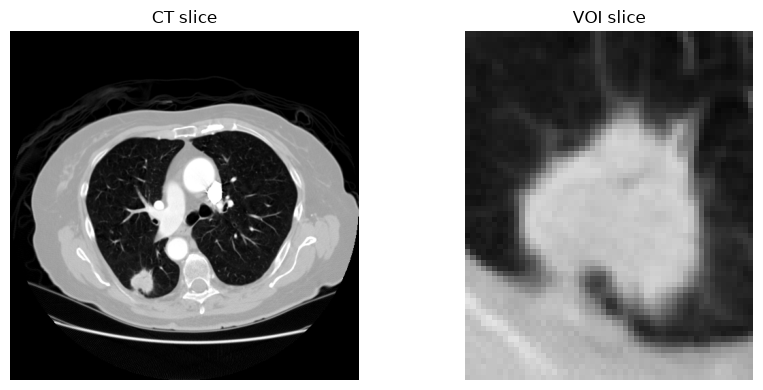

In [201]:
volumes = [ct, voi]
slices = [ct_z, voi_z]
titles = ['CT slice', 'VOI slice']
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for i in range(2):
    img = volumes[i]
    spacing = img.header.get_zooms()
    picture = np.asarray(img.dataobj[:, :, slices[i]]).T
    axes[i].imshow(
        picture,
        cmap='gray',
        origin='lower',
        vmin=-1000,
        vmax=400,
        aspect=spacing[1] / spacing[0]
    )
    axes[i].set_title(titles[i])
    axes[i].axis('off')
plt.tight_layout()
plt.show()

### 1.3 Voxel numbers in this project
We have **994 VOI images**. Each includes a nodule and some tissue around it.
These numbers come from the image files and the checks in Section 5.

| Item | Result |
|---|---|
| Shape along each axis | X: 43-91, Y: 43-109, Z: 2-62 voxels |
| Voxel count per VOI | 3,698-352,000 |
| Voxel count in all 994 VOIs | 20,405,061, including tissue around the nodules |
| Middle spacing (median), X, Y, Z | About 0.70 x 0.70 x 1.25 mm; each file can have different spacing |

The largest VOI is `LIDC-IDRI-0141_R_1.nii.gz`: `80 x 80 x 55 = 352,000` voxels.
This counts the whole VOI, including tissue around the nodule.

The example below has **37,312 voxels**, and its mask marks **6,547** as part of the nodule.
Its spacing is `0.703125 x 0.703125 x 2.5 mm`. The nodule volume is about **8,091.84 mm3**.

We use the mask to compare image values inside and outside the nodule.
We also use the mask count and spacing to find the nodule volume in mm3.
Voxel counts alone do not tell us a nodule's size in mm3, because spacing differs between files.

In [202]:
# Count voxels in the example image and mask.
spacing = voi.header.get_zooms()[:3]
mask_img = nib.load(mask_dir / 'LIDC-IDRI-0001_R_1.nii.gz')
sample_mask = mask_img.get_fdata() > 0
total_voxels = int(np.prod(voi.shape))
nodule_voxels = int(sample_mask.sum())
voxel_volume = float(np.prod(spacing))
nodule_volume = nodule_voxels * voxel_volume

print('Shape (X, Y, Z):', voi.shape)
print('Spacing (X, Y, Z):', np.round(spacing, 3))
print('Spatial unit:', voi.header.get_xyzt_units()[0])
print('Total VOI voxels:', total_voxels)
print('Nodule voxels:', nodule_voxels)
print('Nodule volume (mm3):', round(nodule_volume, 2))

Shape (X, Y, Z): (53, 64, 11)
Spacing (X, Y, Z): [0.703 0.703 2.5  ]
Spatial unit: mm
Total VOI voxels: 37312
Nodule voxels: 6547
Nodule volume (mm3): 8091.84


## 2. Check the data
### 2.1 Missing values and repeated rows
Check both tables for empty cells and rows that appear more than once.
Several annotation rows can refer to the same nodule because it has several sets of scores.

In [203]:
# Dataset size
print('Nodules:', len(nodules))
print('Annotations:', len(annotations))
print('Patients:', nodules['patient_id'].nunique())
print('CT series:', nodules['seriesuid'].nunique())

# Missing values
print('Missing values in nodules:', nodules.isna().sum().sum())
print('Missing values in annotations:', annotations.isna().sum().sum())

# Duplicate rows and keys
print('Duplicate nodule rows:', nodules.duplicated().sum())
print('Duplicate annotation rows:', annotations.duplicated().sum())
print('Duplicate nodule keys:', nodules.duplicated(keys).sum())
print('Repeated annotation keys:', annotations.duplicated(keys).sum())

Nodules: 996
Annotations: 3674
Patients: 551
CT series: 552
Missing values in nodules: 0
Missing values in annotations: 0
Duplicate nodule rows: 0
Duplicate annotation rows: 0
Duplicate nodule keys: 0
Repeated annotation keys: 2677


### 2.2 Check values
Check the score codes, nodule sizes and box coordinates.
The Low/High names may follow voxel order rather than the smallest/largest coordinate in mm.

In [204]:
# Allowed scores from the PDF.
limits = {
    'Malignancy': 5,
    'Calcification': 6,
    'InternalStructure': 4,
    'Lobulation': 5,
    'Margin': 5,
    'Sphericity': 5,
    'Spiculation': 5,
    'Subtlety': 5,
    'Texture': 5
}
invalid_labels = ~nodules['Diagnosis_value'].isin([0, 1])
print('Invalid diagnosis codes:', invalid_labels.sum())
for name, table in [('Nodules', nodules), ('Annotations', annotations)]:
    print(name)
    for feature, maximum in limits.items():
        values = table[feature + '_value']
        invalid = ~values.isin(range(1, maximum + 1))
        print('Invalid ' + feature + ' codes:', invalid.sum())

Invalid diagnosis codes: 0
Nodules
Invalid Malignancy codes: 0
Invalid Calcification codes: 0
Invalid InternalStructure codes: 0
Invalid Lobulation codes: 0
Invalid Margin codes: 0
Invalid Sphericity codes: 0
Invalid Spiculation codes: 0
Invalid Subtlety codes: 0
Invalid Texture codes: 0
Annotations
Invalid Malignancy codes: 0
Invalid Calcification codes: 0
Invalid InternalStructure codes: 0
Invalid Lobulation codes: 0
Invalid Margin codes: 0
Invalid Sphericity codes: 0
Invalid Spiculation codes: 0
Invalid Subtlety codes: 0
Invalid Texture codes: 0


In [205]:
# Check size, number cells and box coordinates.
for name, table in [('Nodules', nodules), ('Annotations', annotations)]:
    print(name)
    print('Diameter <= 0:', (table['diameter_mm'] <= 0).sum())
    numeric = table.select_dtypes('number')
    print('Non-finite numeric values:', (~np.isfinite(numeric)).sum().sum())
    for axis in ['X', 'Y', 'Z']:
        low = table['bboxLow' + axis]
        high = table['bboxHigh' + axis]
        print(axis + ' reversed bounds:', (low > high).sum())
        print(axis + ' equal bounds:', (low == high).sum())

Nodules
Diameter <= 0: 0
Non-finite numeric values: 0
X reversed bounds: 22
X equal bounds: 0
Y reversed bounds: 22
Y equal bounds: 0
Z reversed bounds: 0
Z equal bounds: 2
Annotations
Diameter <= 0: 0
Non-finite numeric values: 0
X reversed bounds: 86
X equal bounds: 0
Y reversed bounds: 86
Y equal bounds: 0
Z reversed bounds: 0
Z equal bounds: 7


In [206]:
# Show five rows with reversed X or Y bounds.
reversed_x = nodules['bboxLowX'] > nodules['bboxHighX']
reversed_y = nodules['bboxLowY'] > nodules['bboxHighY']
reversed_boxes = nodules[reversed_x | reversed_y]
box_columns = [
    'patient_id',
    'nodule_id',
    'bboxLowX',
    'bboxHighX',
    'bboxLowY',
    'bboxHighY'
]
display(reversed_boxes[box_columns].head(5).round(2))

,patient_id,nodule_id,bboxLowX,bboxHighX,bboxLowY,bboxHighY
347,LIDC-IDRI-0262,1,104.04,91.50,33.11,23.08
388,LIDC-IDRI-0311,2,62.73,49.45,-35.94,-50.00
392,LIDC-IDRI-0313,1,-111.61,-144.57,1.76,-26.99
465,LIDC-IDRI-0415,1,115.13,107.86,-33.30,-41.17
466,LIDC-IDRI-0415,3,123.00,115.13,-7.27,-15.74


**Results**

- All checked codes are valid. Diameters are positive, and numeric values have no NaN or infinity.
- **22 nodules** have reversed X/Y bounds. The **86 flagged annotation rows** describe these same 22 nodules. All 22 VOIs have RAS voxel-axis directions.
- Their box corners are ordered when converted back to voxel coordinates. This suggests a coordinate-direction convention, rather than confirmed box errors. RAS alone does not mean bounds must be reversed.
- **2 nodule rows and 7 annotation rows** have equal Z bounds. These still need review before using the boxes to crop images.

Keep the rows; these flags alone are not enough to remove them.

### 2.3 Count files and find missing images
A full CT can show several nodules. Each VOI is cut around one nodule.
Compare the image files with the table to find missing images and masks.

In [207]:
# Count local files.
ct_files = list((root / 'CT/CT/image').glob('*.nii.gz'))
ct_mask_files = list((root / 'CT/CT/nodule_mask').glob('*.nii.gz'))
print('CT volumes:', len(ct_files))
print('CT masks:', len(ct_mask_files))
print('VOI images:', len(images))
print('VOI masks:', len(masks))

# Find metadata rows without matching files.
missing_images = nodules[~nodules['image'].isin(images.keys())]
missing_masks = nodules[~nodules['image'].isin(masks.keys())]
print('Missing VOI images:', len(missing_images))
print('Missing VOI masks:', len(missing_masks))
display(missing_images[['patient_id', 'nodule_id', 'Diagnosis', 'image']])

CT volumes: 3
CT masks: 6
VOI images: 994
VOI masks: 996
Missing VOI images: 2
Missing VOI masks: 0


,patient_id,nodule_id,Diagnosis,image
977,LIDC-IDRI-1002,1,Malign,LIDC-IDRI-1002_R_1.nii.gz
978,LIDC-IDRI-1002,2,Malign,LIDC-IDRI-1002_R_2.nii.gz


**Results**

- The CT folders have **3 full CT images** and **6 nodule masks**. The table lists **552 CT series**,
  so many full CT files are not in this project folder.
- There are **994 VOI images** and **996 VOI masks** for **996 nodules**.
  All listed nodules have masks, but two have no VOI image.
- The missing images are for **nodules 1 and 2 of LIDC-IDRI-1002**. Both have the label `Malign`.
  Their table rows and masks are still here.

Image checks use **994 nodules: 650 Benign and 344 Malign**.
Table checks can use all **996 nodules: 650 Benign and 346 Malign**.
Keep the two rows and report that their images are missing.

### 2.4 Count nodules and score records
A patient can have several nodules. A nodule can have several score records.
We cannot count different doctors from these rows because there is no doctor ID.

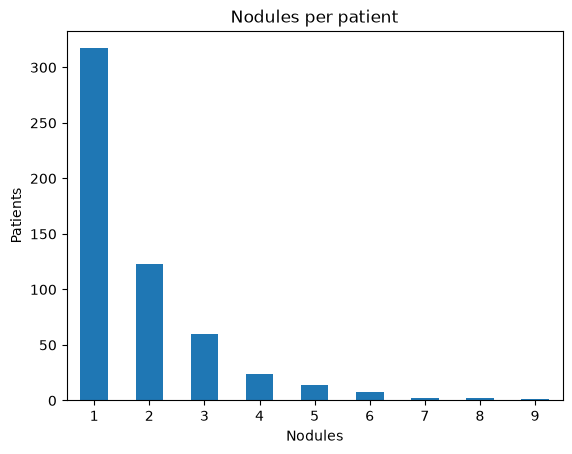

In [208]:
# Count nodules, then count patients with each nodule count.
nodules_per_patient = nodules.groupby('patient_id').size()
patient_counts = nodules_per_patient.value_counts()
patient_counts = patient_counts.sort_index()
patient_counts.plot.bar(
    title='Nodules per patient',
    xlabel='Nodules',
    ylabel='Patients',
    rot=0
)
plt.show()

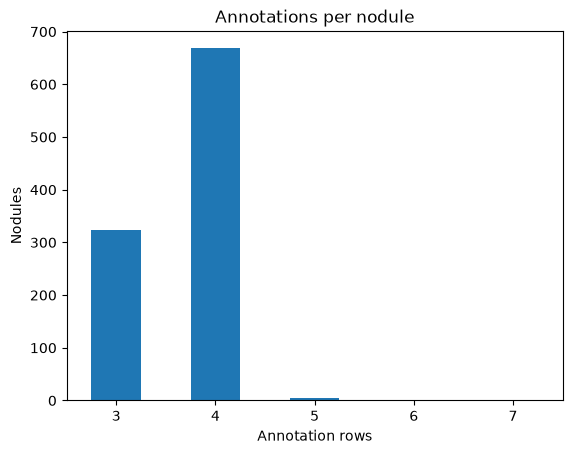

In [209]:
# Count score records for each nodule and CT.
annotations_per_nodule = annotations.groupby(keys).size()
annotation_counts = annotations_per_nodule.value_counts()
annotation_counts = annotation_counts.sort_index()
annotation_counts.plot.bar(
    title='Annotations per nodule',
    xlabel='Annotation rows',
    ylabel='Nodules',
    rot=0
)
plt.show()

**Results**

- **317 of 551 patients have one nodule**. Each patient has **1-9 nodules**.
- **323** nodule/CT pairs have **3 score records**, and **668** have **4**. Only **6** have 5-7 records.

The score table has **997 nodule/CT pairs**. One is missing from the nodule table; Section 4 checks it.

## 3. Nodule labels and features
### 3.1 Count labels and scores
A `Malignancy_value` score of **3** means the doctor was unsure about cancer.
`Diagnosis` uses the individual scores, so the one saved score for a nodule is not enough to rebuild its label.

In [210]:
# Count labels and find their percentages.
counts = nodules['Diagnosis'].value_counts()
percent = (counts / len(nodules) * 100).round(1)
label_summary = pd.DataFrame({
    'count': counts,
    'percent': percent
})
display(label_summary)

score_labels = pd.crosstab(
    nodules['Malignancy_value'],
    nodules['Diagnosis']
)
display(score_labels)

,count,percent
Diagnosis,,
Benign,650,65.3
Malign,346,34.7


Diagnosis,Benign,Malign
Malignancy_value,,
1,154,8
2,183,32
3,313,51
4,0,119
5,0,136


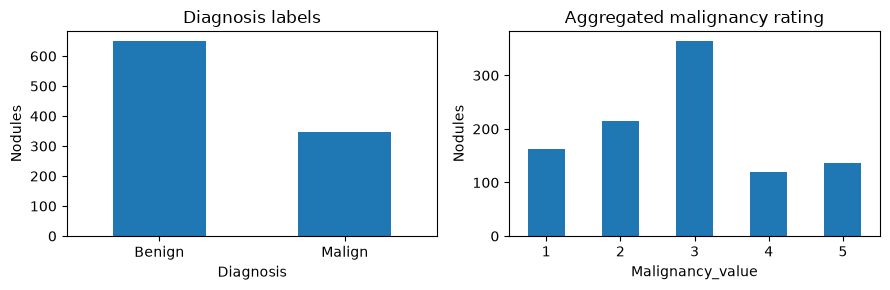

In [211]:
ratings = nodules['Malignancy_value'].value_counts()
ratings = ratings.sort_index()
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
counts.plot.bar(
    ax=axes[0],
    title='Diagnosis labels',
    rot=0
)
ratings.plot.bar(
    ax=axes[1],
    title='Aggregated malignancy rating',
    rot=0
)
for ax in axes:
    ax.set_ylabel('Nodules')
plt.tight_layout()
plt.show()

### 3.2 Nodule sizes
Use the IQR rule to mark sizes far from the middle half of the data.
A marked size may still be correct. Check it before removing the row.

In [212]:
# Mark unusually small or large sizes.
diameter = nodules['diameter_mm']
size_summary = nodules.groupby('Diagnosis')['diameter_mm'].describe()
display(size_summary.round(2))
q1, q3 = diameter.quantile([0.25, 0.75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
size_outliers = nodules[(diameter < lower) | (diameter > upper)]
print('IQR flags:', len(size_outliers))
print('Median diameter (mm):', round(diameter.median(), 2))
largest_outliers = size_outliers.nlargest(5, 'diameter_mm')
columns = keys + ['Diagnosis', 'diameter_mm']
display(largest_outliers[columns])

,count,mean,std,min,25%,50%,75%,max
Diagnosis,,,,,,,,
Benign,650.0,6.25,2.34,3.25,4.86,5.74,6.92,26.84
Malign,346.0,13.28,5.27,4.33,8.99,12.46,16.94,32.27


IQR flags: 66
Median diameter (mm): 6.77


,patient_id,nodule_id,seriesuid,Diagnosis,diameter_mm
99,LIDC-IDRI-0061,6,1.3.6.1.4.1.14519.5.2.1.6279.6001.287966244644...,Malign,32.270030
786,LIDC-IDRI-0772,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.112740418331...,Malign,30.610406
731,LIDC-IDRI-0697,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.943403138251...,Malign,27.442423
192,LIDC-IDRI-0139,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.481278873893...,Malign,27.075443
101,LIDC-IDRI-0064,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.487268565754...,Benign,26.837081


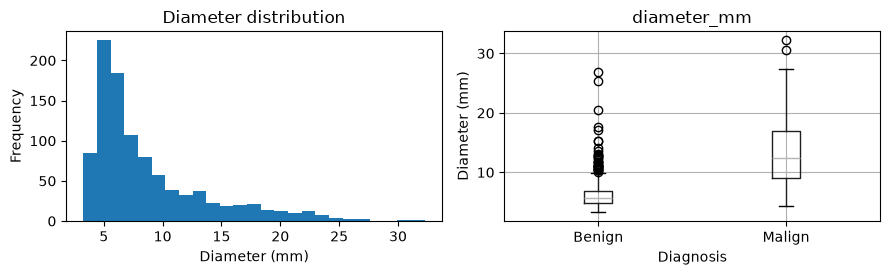

In [213]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
diameter.plot.hist(
    ax=axes[0],
    bins=25,
    title='Diameter distribution'
)
axes[0].set_xlabel('Diameter (mm)')
nodules.boxplot(
    column='diameter_mm',
    by='Diagnosis',
    ax=axes[1]
)
axes[1].set_ylabel('Diameter (mm)')
fig.suptitle('')
plt.tight_layout()
plt.show()

### 3.3 Correlations
The heatmap shows Spearman correlations for all 22 numeric columns.
The table ranks the 10 strongest positive pairs and 10 strongest negative pairs.
Positive means the values tend to rise together. Negative means one tends to fall as the other rises.

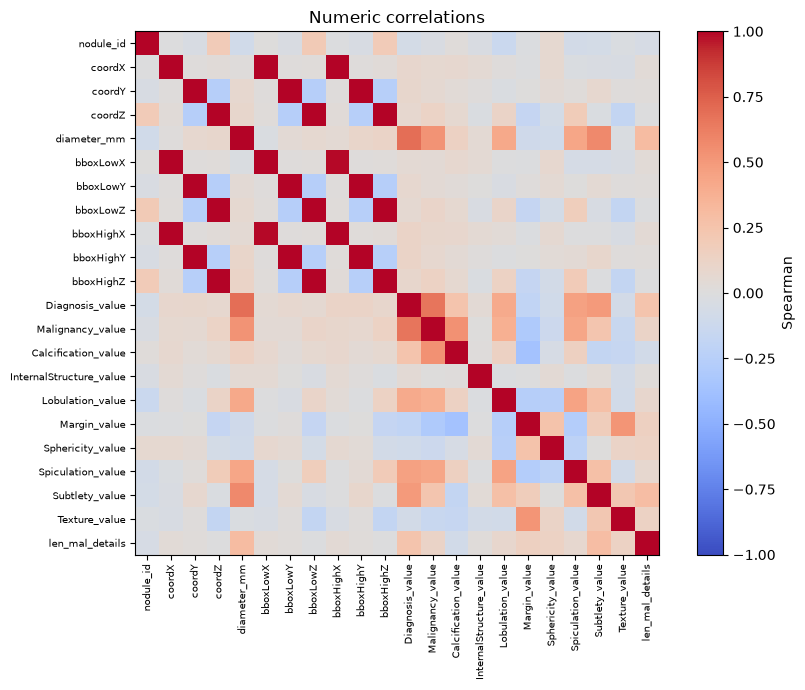

In [214]:
numeric = nodules.select_dtypes(include='number')
spearman = numeric.corr(method='spearman')

# Use the same scale for all columns.
plt.figure(figsize=(9, 7))
plt.imshow(spearman, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(
    range(len(spearman)), spearman.columns,
    rotation=90, fontsize=7
)
plt.yticks(range(len(spearman)), spearman.index, fontsize=7)
plt.colorbar(label='Spearman')
plt.title('Numeric correlations')
plt.tight_layout()
plt.show()

In [215]:
# Keep each pair once and skip self-pairs.
features = list(spearman.columns)
rows = []
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        first, second = features[i], features[j]
        rows.append([first, second, spearman.loc[first, second]])

correlations = pd.DataFrame(rows, columns=['Column 1', 'Column 2', 'Spearman'])
positive = correlations[correlations['Spearman'] > 0].nlargest(10, 'Spearman')
negative = correlations[correlations['Spearman'] < 0].nsmallest(10, 'Spearman')

positive['Sign'] = 'Positive'
negative['Sign'] = 'Negative'
positive['Rank'] = range(1, len(positive) + 1)
negative['Rank'] = range(1, len(negative) + 1)
ranking = pd.concat([positive, negative], ignore_index=True)
ranking = ranking[['Sign', 'Rank', 'Column 1', 'Column 2', 'Spearman']]
display(ranking.round(3))

,Sign,Rank,Column 1,Column 2,Spearman
0,Positive,1,coordZ,bboxHighZ,0.999
1,Positive,2,coordZ,bboxLowZ,0.999
2,Positive,3,coordY,bboxLowY,0.998
3,Positive,4,coordY,bboxHighY,0.998
4,Positive,5,coordX,bboxLowX,0.998
5,Positive,6,bboxLowZ,bboxHighZ,0.998
6,Positive,7,coordX,bboxHighX,0.998
7,Positive,8,bboxLowY,bboxHighY,0.994
8,Positive,9,bboxLowX,bboxHighX,0.992
9,Positive,10,diameter_mm,Diagnosis_value,0.694


**Results**

- Most top positive pairs are center and box coordinates. They describe the same location, so their correlations are close to **1**.
- `diameter_mm` and `Diagnosis_value` rank **10th** in the positive group (**0.694**).
- `Calcification_value` and `Margin_value` have the strongest negative correlation (**-0.360**). This is a small to moderate link; the calcification values are category codes.
- With `Malignancy_value`, `diameter_mm` has **0.527**, `Spiculation_value` **0.437**, and `Margin_value` **-0.301**.

IDs, category codes and labels need care when reading these numbers. A correlation does not prove cause.
More details are in [EDA_results.md](EDA_results.md).

### 3.4 Feature distributions by diagnosis
Compare each feature in the Benign and Malign groups.
Use percentages because the groups have different sizes.
Keep the feature names from the Excel file.
`Calcification` and `InternalStructure` use category codes, not low-to-high scores.
The dataset PDF explains each code.

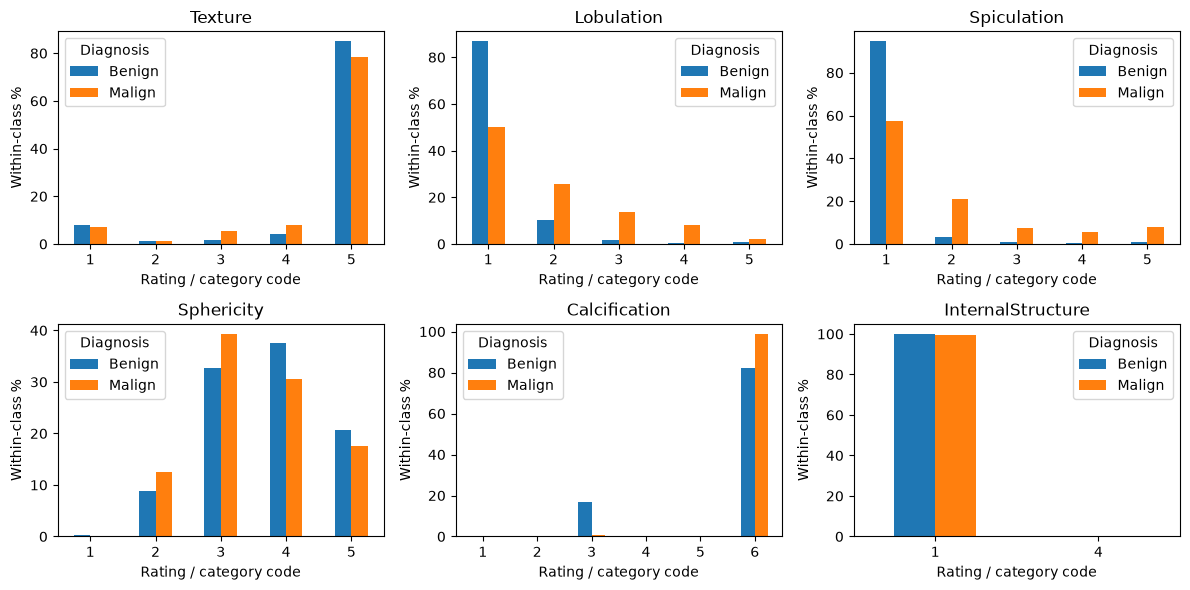

In [216]:
rating_features = [
    'Texture',
    'Lobulation',
    'Spiculation',
    'Sphericity',
    'Calcification',
    'InternalStructure'
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for feature, ax in zip(rating_features, axes.flat):
    percentages = pd.crosstab(
        nodules[feature + '_value'],
        nodules['Diagnosis'],
        normalize='columns'
    ) * 100
    percentages.plot.bar(
        ax=ax,
        title=feature,
        rot=0
    )
    ax.set(
        xlabel='Rating / category code',
        ylabel='Within-class %'
    )
plt.tight_layout()
plt.show()

## 4. Check doctors' scores
The PDF gives this rule: label a nodule `Malign` when at least two score records have
`Malignancy_value > 3`. Otherwise, label it `Benign`.
Match rows using patient ID, nodule ID and CT series ID to keep different scans apart.
Compare the highest and lowest scores to see how much they differ.
This checks the scores and labels; it cannot tell us whether a nodule is truly cancer.

### 4.1 Check labels and score counts

In [217]:
# Collect scores for each nodule and CT.
votes = annotations.copy()
votes['high_vote'] = votes['Malignancy_value'] > 3
groups = votes.groupby(keys)
ratings = pd.DataFrame()
ratings['annotation_count'] = groups.size()
ratings['min_rating'] = groups['Malignancy_value'].min()
ratings['max_rating'] = groups['Malignancy_value'].max()
ratings['high_votes'] = groups['high_vote'].sum()
ratings['rating_range'] = ratings['max_rating'] - ratings['min_rating']
ratings = ratings.reset_index()

In [218]:
# Add one score summary to each nodule row.
checks = nodules.merge(
    ratings,
    on=keys,
    how='left',
    validate='one_to_one'
)
checks['expected_label'] = 'Benign'
checks.loc[checks['high_votes'] >= 2, 'expected_label'] = 'Malign'
missing_scores = checks['annotation_count'].isna()
checks.loc[missing_scores, 'expected_label'] = pd.NA

different_labels = checks['Diagnosis'] != checks['expected_label']
different_counts = checks['annotation_count'] != checks['len_mal_details']
print('Missing rating groups:', missing_scores.sum())
print('Label mismatches:', (~missing_scores & different_labels).sum())
print('Annotation count mismatches:', different_counts.sum())

Missing rating groups: 0
Label mismatches: 0
Annotation count mismatches: 0


**Results**

All **996 listed nodules** have score records. There are **0 label mismatches** and
**0 score-count mismatches**. The labels follow the PDF rule, and the counts match
`len_mal_details`. This does not prove that each label is medically correct.

### 4.2 Find extra score records

In [219]:
# Find score groups that are missing from the nodule table.
extra = ratings.merge(
    nodules[keys],
    on=keys,
    how='left',
    indicator=True
)
extra_groups = extra[extra['_merge'] == 'left_only']
display(extra_groups[keys + ['annotation_count']])

,patient_id,nodule_id,seriesuid,annotation_count
401,LIDC-IDRI-0332,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.316900421002...,4


**Results**

One extra group has **4 score records** for **LIDC-IDRI-0332, nodule 1**, in another CT series.
It is missing from the nodule table. This explains the **997 score groups vs 996 listed nodules**.
Using `seriesuid` in the join keeps these records apart.

### 4.3 Compare scores for the same nodule

Identical ratings: 136
Rating range >= 3: 142


,patient_id,nodule_id,seriesuid,min_rating,max_rating,high_votes,Diagnosis
124,LIDC-IDRI-0081,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.172243743899...,1,5,2,Malign
186,LIDC-IDRI-0130,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.257515388956...,1,5,1,Benign
195,LIDC-IDRI-0141,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.267957701183...,1,5,2,Malign
348,LIDC-IDRI-0264,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.262873069163...,1,5,1,Benign
349,LIDC-IDRI-0264,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.262873069163...,1,5,2,Malign


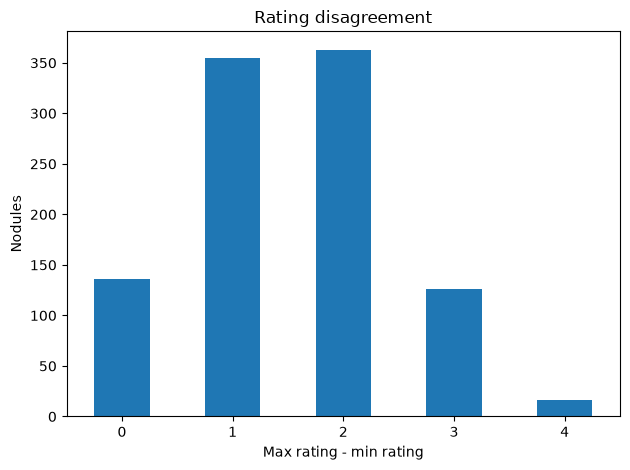

In [220]:
# Compare the highest and lowest scores.
same_scores = checks['rating_range'] == 0
large_gaps = checks['rating_range'] >= 3
print('Identical ratings:', same_scores.sum())
print('Rating range >= 3:', large_gaps.sum())
largest_gaps = checks.nlargest(5, 'rating_range')
columns = keys + ['min_rating', 'max_rating', 'high_votes', 'Diagnosis']
display(largest_gaps[columns])

gap_counts = checks['rating_range'].value_counts().sort_index()
gap_counts.plot.bar(
    title='Rating disagreement',
    xlabel='Max rating - min rating',
    ylabel='Nodules',
    rot=0
)
plt.tight_layout()
plt.show()

**Results**

- **136 nodules (13.7%)** have the same score in every record. Most nodules have some score differences.
- **142 nodules (14.3%)** have a gap of at least 3 points between their highest and lowest scores.

For example, **LIDC-IDRI-0141, nodule 1** has scores **1, 2, 5 and 4**.
Two scores are above 3, so its label is `Malign`, even though the scores differ a lot.
A single label does not show these differences.

## 5. Check 3D images and masks
### 5.1 Read the files
Read each image and mask, then collect the numbers below.
Check that masks have only 0 and 1, contain no NaN or infinity, and match their images in size and position.
Also count separate mask parts; voxels touching at a face, edge or corner count as connected.
Use pairs that pass these checks to compare image values. The unit used for image values has not been checked here.

In [221]:
# Read image size, spacing and values.
image_rows = []
for name, path in images.items():
    img = nib.load(path)
    data = img.get_fdata(dtype=np.float32)
    size_x, size_y, size_z = img.shape
    spacing_x, spacing_y, spacing_z = img.header.get_zooms()[:3]
    direction = ''.join(nib.aff2axcodes(img.affine))
    image_rows.append({
        'image': name,
        'size_x': size_x,
        'size_y': size_y,
        'size_z': size_z,
        'spacing_x': spacing_x,
        'spacing_y': spacing_y,
        'spacing_z': spacing_z,
        'total_voxels': int(np.prod(img.shape)),
        'orientation': direction,
        'finite': bool(np.isfinite(data).all()),
        'min': data.min(),
        'max': data.max()
    })
image_stats = pd.DataFrame(image_rows)

In [222]:
# Count nodule voxels and separate mask parts.
mask_rows = []
for name, path in masks.items():
    img = nib.load(path)
    data = img.get_fdata(dtype=np.float32)
    mask = data > 0
    voxels = int(mask.sum())
    voxel_volume = float(np.prod(img.header.get_zooms()[:3]))
    regions, components = ndimage.label(
        mask,
        structure=np.ones((3, 3, 3))
    )
    # Count voxels in each part, leaving out the background.
    part_sizes = np.bincount(regions.ravel())[1:]
    largest_fraction = np.nan
    if voxels > 0:
        largest_fraction = part_sizes.max() / voxels
    mask_rows.append({
        'image': name,
        'voxels': voxels,
        'volume_mm3': voxels * voxel_volume,
        'finite': bool(np.isfinite(data).all()),
        'binary': bool(np.isin(data, [0, 1]).all()),
        'components': components,
        'largest_fraction': largest_fraction
    })
mask_stats = pd.DataFrame(mask_rows)

In [223]:
# Check whether each mask matches its image.
mask_stats['has_image'] = mask_stats['image'].isin(images.keys())
mask_stats['shape_ok'] = None
mask_stats['affine_ok'] = None
for name in images:
    if name not in masks:
        continue
    img = nib.load(images[name])
    mask_img = nib.load(masks[name])
    row = mask_stats['image'] == name
    mask_stats.loc[row, 'shape_ok'] = img.shape == mask_img.shape
    mask_stats.loc[row, 'affine_ok'] = np.allclose(img.affine, mask_img.affine)

In [224]:
# Keep pairs that pass the mask and position checks.
valid_pairs = mask_stats[mask_stats['has_image']]
valid_pairs = valid_pairs[valid_pairs['finite']]
valid_pairs = valid_pairs[valid_pairs['binary']]
valid_pairs = valid_pairs[valid_pairs['voxels'] > 0]
valid_pairs = valid_pairs[valid_pairs['shape_ok'] == True]
valid_pairs = valid_pairs[valid_pairs['affine_ok'] == True]

In [225]:
# Measure values inside and outside each nodule.
intensity_rows = []
for name in valid_pairs['image']:
    img = nib.load(images[name])
    mask_img = nib.load(masks[name])
    data = img.get_fdata(dtype=np.float32)
    mask = mask_img.get_fdata() > 0
    if not np.isfinite(data).all():
        continue
    inside = data[mask]
    outside = data[~mask]
    outside_mean = np.nan
    if outside.size > 0:
        outside_mean = outside.mean()
    intensity_rows.append({
        'image': name,
        'inside_mean': inside.mean(),
        'inside_std': inside.std(),
        'outside_mean': outside_mean
    })
intensities = pd.DataFrame(intensity_rows)

In [226]:
# Add patient IDs and labels to the image results.
image_labels = nodules[['image', 'patient_id', 'Diagnosis']]
intensities = intensities.merge(
    image_labels,
    on='image',
    how='left',
    validate='one_to_one'
)

**Results**

We can use all **994 available image-mask pairs** for the image-value checks.
The two masks without images stay in the mask checks, but cannot be used to measure image values.

### 5.2 Image sizes, spacing and mask checks
Read the size and spacing tables, then check the mask counts.
The `50%` row in `describe()` is the middle value (median).

In [227]:
display(image_stats.describe().round(2))
print('Total voxels across all VOI images:', image_stats['total_voxels'].sum())
direction_counts = image_stats['orientation'].value_counts()
display(direction_counts.to_frame('images'))
print('Non-finite images:', (image_stats['finite'] == False).sum())

,size_x,size_y,size_z,spacing_x,spacing_y,spacing_z,total_voxels,min,max
count,994.00,994.00,994.00,994.00,994.00,994.00,994.00,994.00,994.00
mean,44.85,44.80,9.07,0.70,0.70,1.51,20528.23,-988.07,834.52
std,5.42,5.49,7.64,0.08,0.08,0.69,28416.37,48.74,598.94
min,43.00,43.00,2.00,0.46,0.46,0.45,3698.00,-1445.00,-506.00
25%,43.00,43.00,4.00,0.64,0.64,1.00,7568.00,-1024.00,299.75
50%,44.00,44.00,6.00,0.70,0.70,1.25,11352.00,-1005.00,828.50
75%,44.00,44.00,11.00,0.74,0.74,2.50,21296.00,-960.00,1201.50
max,91.00,109.00,62.00,0.98,0.98,2.50,352000.00,-789.00,3071.00


Total voxels across all VOI images: 20405061


,images
orientation,
LPS,972
RAS,22


Non-finite images: 0


**Image results**

- VOIs have **2-62 slices** and **3,698-352,000 voxels** each, so image sizes differ.
- The middle spacing is about **0.70 x 0.70 x 1.25 mm**. The Z gap is usually larger than the X/Y gaps.
- There are **972 LPS** and **22 RAS** images. Their stored axis directions differ; the previews turn them to the same directions.
- No images contain NaN or infinity.

Voxel count alone is not size in mm3. Use spacing too, and choose a shared size and spacing rule for model inputs.

In [228]:
print('Empty masks:', (mask_stats['voxels'] == 0).sum())
print('Non-finite masks:', (mask_stats['finite'] == False).sum())
print('Non-binary masks:', (mask_stats['binary'] == False).sum())
print('Masks with multiple regions:', (mask_stats['components'] > 1).sum())
print('Masks without images:', (mask_stats['has_image'] == False).sum())
print('Shape mismatches:', (mask_stats['shape_ok'] == False).sum())
print('Affine mismatches:', (mask_stats['affine_ok'] == False).sum())

columns = ['voxels', 'volume_mm3', 'components', 'largest_fraction']
display(mask_stats[columns].describe().round(3))
separate_masks = mask_stats[mask_stats['components'] > 1]
display(separate_masks.sort_values('largest_fraction').head(5))

Empty masks: 0
Non-finite masks: 0
Non-binary masks: 0
Masks with multiple regions: 35
Masks without images: 2
Shape mismatches: 0
Affine mismatches: 0


,voxels,volume_mm3,components,largest_fraction
count,996.000,996.000,996.000,996.000
mean,1512.105,1068.580,1.050,1.000
std,2994.229,2136.885,0.335,0.008
min,36.000,29.182,1.000,0.734
25%,188.750,112.936,1.000,1.000
50%,401.000,235.910,1.000,1.000
75%,1271.500,840.763,1.000,1.000
max,33157.000,19603.604,8.000,1.000


,image,voxels,volume_mm3,finite,binary,components,largest_fraction,has_image,shape_ok,affine_ok
246,LIDC-IDRI-0179_R_9.nii.gz,402,496.856689,True,True,2,0.733831,True,True,True
669,LIDC-IDRI-0634_R_2.nii.gz,392,258.667603,True,True,2,0.984694,True,True,True
236,LIDC-IDRI-0171_R_1.nii.gz,1564,2887.634277,True,True,2,0.989130,True,True,True
736,LIDC-IDRI-0701_R_4.nii.gz,5575,2251.128902,True,True,8,0.993184,True,True,True
879,LIDC-IDRI-0866_R_9.nii.gz,296,182.922346,True,True,2,0.993243,True,True,True


**Mask results**

- All **996 masks** contain nodule voxels, use only **0 and 1**, and have no NaN or infinity.
- All **994 available pairs** match in shape and position. Two masks have no image.
- **35 masks** have more than one part. Check them before removing anything.
- The middle mask volume is **235.91 mm3**, while the average is **1,068.58 mm3**. Large nodules raise the average.

For `LIDC-IDRI-0179_R_9`, `largest_fraction` is about **0.734**:
only **73.4%** of its mask voxels are in the largest part. This case needs a closer look.
Matching size and position does not prove that every mask outline is correct.

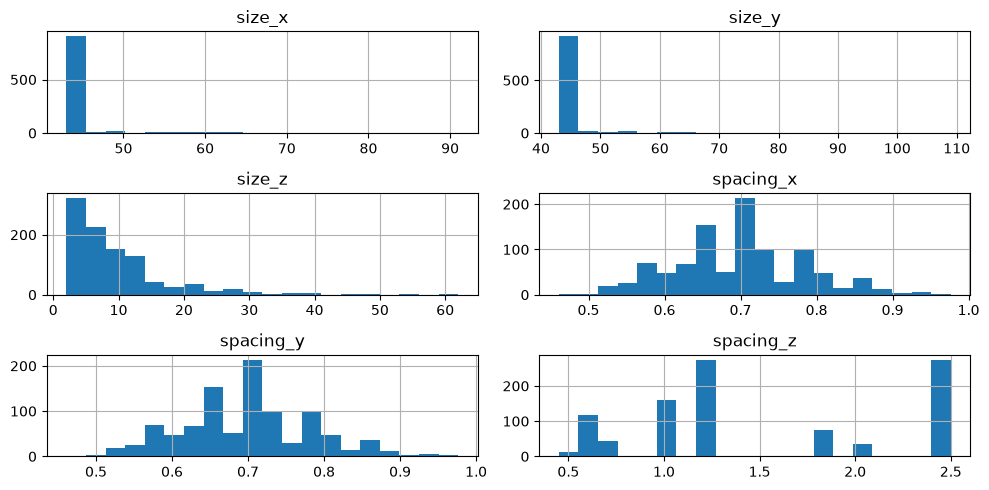

In [229]:
# Show size and spacing for all images.
sizes = image_stats[['size_x', 'size_y', 'size_z']]
spacings = image_stats[['spacing_x', 'spacing_y', 'spacing_z']]
dimensions = pd.concat([sizes, spacings], axis=1)
dimensions.hist(
    bins=20,
    figsize=(10, 5)
)
plt.tight_layout()
plt.show()

**What the plots show**

VOI depth and spacing vary between files. A stack with more slices does not always mean a larger nodule,
because the VOI also includes nearby tissue and the slice spacing can differ.

### 5.3 Show images with masks
Show one example from each label group and one mask with separate parts.
Pick the slice with the largest nodule mask. Use spacing to keep the picture's shape correct.
These few pictures are examples; they do not show whether every mask is correct.

In [230]:
# Pick one example per label and one mask with separate parts.
valid = intensities.merge(
    mask_stats[['image', 'components']],
    on='image',
    validate='one_to_one'
)
benign = valid[valid['Diagnosis'] == 'Benign'].head(1)
malign = valid[valid['Diagnosis'] == 'Malign'].head(1)
separate = valid[valid['components'] > 1].head(1)
samples = pd.concat([benign, malign, separate])
samples = samples.drop_duplicates('image')

In [231]:
# Read the selected slices before plotting.
pictures = []
overlays = []
aspects = []
titles = []
for i in range(len(samples)):
    row = samples.iloc[i]
    name = row['image']
    img = nib.load(images[name])
    mask_img = nib.load(masks[name])
    img = nib.as_closest_canonical(img)
    mask_img = nib.as_closest_canonical(mask_img)
    data = img.get_fdata()
    mask = mask_img.get_fdata() > 0
    areas = mask.sum(axis=(0, 1))
    z = int(areas.argmax())
    spacing = img.header.get_zooms()
    picture = data[:, :, z].T
    mask_slice = mask[:, :, z].T
    overlay = np.ma.masked_where(mask_slice == 0, mask_slice)
    title = f"{row['Diagnosis']} | {row['components']} region(s)\n{name}"
    pictures.append(picture)
    overlays.append(overlay)
    aspects.append(spacing[1] / spacing[0])
    titles.append(title)

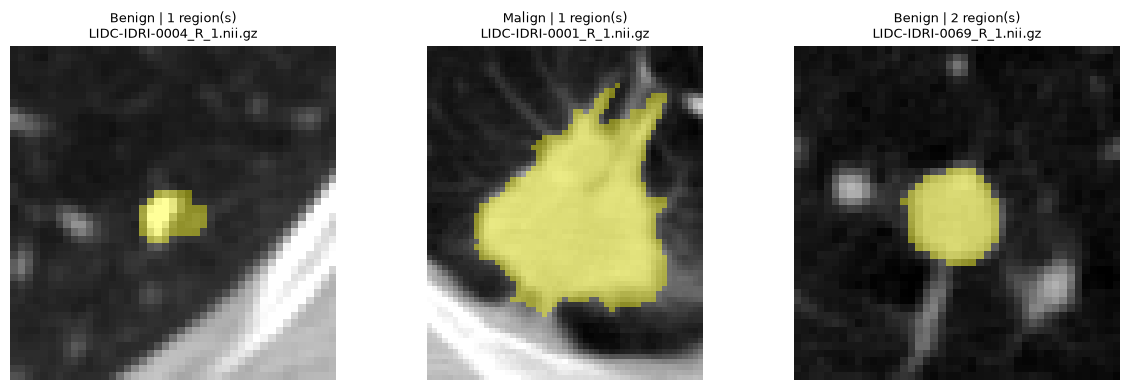

In [232]:
fig, axes = plt.subplots(
    1, len(samples),
    figsize=(12, 4),
    squeeze=False
)
for i in range(len(samples)):
    ax = axes[0, i]
    ax.imshow(
        pictures[i],
        cmap='gray',
        origin='lower',
        vmin=-1000,
        vmax=400,
        aspect=aspects[i]
    )
    ax.imshow(
        overlays[i],
        cmap='autumn',
        origin='lower',
        alpha=0.4,
        vmin=0,
        vmax=1,
        aspect=aspects[i]
    )
    ax.set_title(titles[i], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

**What the examples show**

The colored area marks the nodule on the shown slice.
The example `LIDC-IDRI-0069_R_1` has **2 mask parts in 3D**; one slice may not show both.
Look at nearby slices before deciding whether a separate part is a problem.
These examples do not check every mask.

### 5.4 Volume and intensity by diagnosis
Compare one set of numbers per nodule between the Benign and Malign groups.
"Outside" means the part of the VOI outside the mask.
Look at how much the groups overlap, as well as their averages.

In [233]:
# Add mask volume to the image results.
volumes = mask_stats[['image', 'volume_mm3']]
analysis = intensities.merge(
    volumes,
    on='image',
    validate='one_to_one'
)
print('Valid image-mask pairs:', len(analysis))
print('Excluded images:', len(images) - len(analysis))
print('Pairs without labels:', analysis['Diagnosis'].isna().sum())

Valid image-mask pairs: 994
Excluded images: 0
Pairs without labels: 0


**Results**

All **994 available images** are used, and all have labels: **650 Benign** and **344 Malign**.
The two missing VOI images are outside this image analysis; they remain in the table analysis.

In [234]:
columns = ['volume_mm3', 'inside_mean', 'inside_std', 'outside_mean']
group_stats = analysis.groupby('Diagnosis')[columns]
summary_stats = group_stats.agg(['count', 'mean', 'median'])
display(summary_stats.round(2))

volume_mm3                   inside_mean                          \
               count     mean   median       count        mean      median   
Diagnosis                                                                    
Benign           650   281.94   147.82         650 -303.390015 -349.579987   
Malign           344  2541.27  1357.56         344 -265.869995 -240.089996   

          inside_std                         outside_mean              \
               count        mean      median        count        mean   
Diagnosis                                                               
Benign           650  282.250000  231.580002          650 -655.609985   
Malign           344  253.649994  251.820007          344 -663.159973   

                       
               median  
Diagnosis              
Benign    -678.789978  
Malign    -691.200012

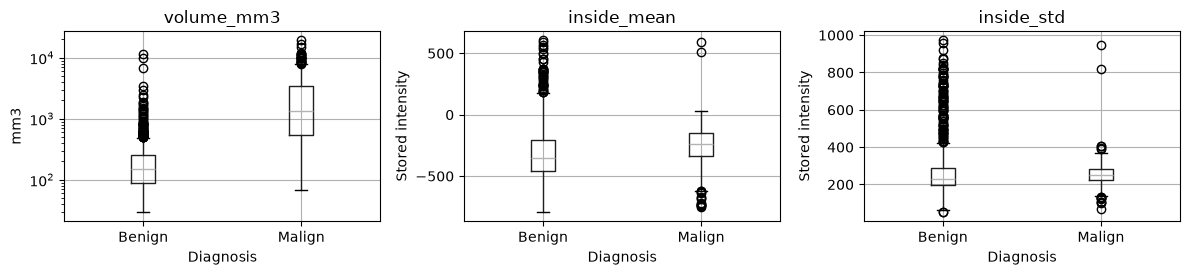

In [235]:
columns = ['volume_mm3', 'inside_mean', 'inside_std']
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for i in range(3):
    column = columns[i]
    analysis.boxplot(
        column=column,
        by='Diagnosis',
        ax=axes[i]
    )
    if column == 'volume_mm3':
        axes[i].set_ylabel('mm3')
    else:
        axes[i].set_ylabel('Stored intensity')
axes[0].set_yscale('log')
fig.suptitle('')
plt.tight_layout()
plt.show()

**Results**

- Average `volume_mm3` is **281.94 for Benign** and **2,541.27 for Malign**. The Malign group has larger nodules on average, but the plots still overlap.
- Average `inside_mean` is **-303.39 for Benign** and **-265.87 for Malign**. Malign values are higher on average, but there is no clear cutoff between the groups.
- Average `inside_std` is **282.25 vs 253.65**. Both groups show a wide spread in the plot.
- Average `outside_mean` is close: **-655.61 vs -663.16**. These values come from tissue outside the mask within the VOI.

Each nodule contributes one set of numbers. These are stored image values; their HU units have not been checked here.

## 6. Feature engineering
Create simple features using the 994 available image-mask pairs. Keep the original feature names.

### 6.1 Create new features
| Feature | Meaning |
|---|---|
| `log_volume` | Log of 1 + mask volume; compresses large values. |
| `intensity_difference` | Mean inside the mask minus mean outside it, within the VOI. |
| `inside_median` | Middle image value inside the nodule. |
| `inside_iqr` | Percentile 75 minus percentile 25 inside the nodule. |
| `mask_size_x_mm`, `mask_size_y_mm`, `mask_size_z_mm` | Width of the smallest box around the mask along each axis, using spacing. |
| `mask_fill_ratio` | Nodule voxel count divided by voxel count in that small box. |

The sizes describe the mask, not the whole VOI. Turn masks to the same axis directions before measuring them. All mask parts are included in the box.
These features need a nodule mask when used for predictions. The image files stay unchanged.

In [236]:
# Add the original diameter to the image measurements.
feature_data = analysis.merge(
    nodules[['image', 'diameter_mm']],
    on='image',
    validate='one_to_one'
)
feature_data['log_volume'] = np.log1p(feature_data['volume_mm3'])
feature_data['intensity_difference'] = (
    feature_data['inside_mean'] - feature_data['outside_mean']
)

In [237]:
# Measure the middle value and spread inside each mask.
rows = []
for name in feature_data['image']:
    data = nib.load(images[name]).get_fdata(dtype=np.float32)
    mask = nib.load(masks[name]).get_fdata() > 0
    inside = data[mask]
    q1, q3 = np.percentile(inside, [25, 75])
    rows.append([name, np.median(inside), q3 - q1])

extra_intensity = pd.DataFrame(
    rows,
    columns=['image', 'inside_median', 'inside_iqr']
)

In [238]:
# Use the mask's small box, including the end voxels.
rows = []
for name in feature_data['image']:
    img = nib.as_closest_canonical(nib.load(masks[name]))
    mask = img.get_fdata() > 0
    x, y, z = np.where(mask)
    size = np.array([
        x.max() - x.min() + 1,
        y.max() - y.min() + 1,
        z.max() - z.min() + 1
    ])
    size_mm = size * np.array(img.header.get_zooms()[:3])
    fill_ratio = mask.sum() / np.prod(size)
    rows.append([
        name, size_mm[0], size_mm[1], size_mm[2], fill_ratio
    ])

mask_features = pd.DataFrame(
    rows,
    columns=[
        'image', 'mask_size_x_mm', 'mask_size_y_mm',
        'mask_size_z_mm', 'mask_fill_ratio'
    ]
)

In [239]:
feature_data = feature_data.merge(extra_intensity, on='image', validate='one_to_one')
feature_data = feature_data.merge(mask_features, on='image', validate='one_to_one')
new_features = [
    'log_volume',
    'intensity_difference',
    'inside_median',
    'inside_iqr',
    'mask_size_x_mm',
    'mask_size_y_mm',
    'mask_size_z_mm',
    'mask_fill_ratio'
]
# Show three examples with features on separate rows.
display(feature_data[new_features].head(3).T.round(2))

,0,1,2
log_volume,9.00,9.21,6.32
intensity_difference,458.40,421.48,174.07
inside_median,-56.00,-455.00,-507.00
inside_iqr,486.00,578.00,455.00
mask_size_x_mm,28.83,35.27,13.12
mask_size_y_mm,35.16,31.17,9.02
mask_size_z_mm,22.50,25.00,10.00
mask_fill_ratio,0.35,0.36,0.47


### 6.2 Compare the new features
Show the mean and median for each label group. A group difference does not prove that a feature will improve a model.
`inside_iqr` measures spread, not the average image value. `mask_fill_ratio` measures box occupancy; it does not directly measure roundness.

In [240]:
feature_summary = feature_data.groupby('Diagnosis')[new_features]
feature_summary = feature_summary.agg(['mean', 'median'])
display(feature_summary.T.round(2))

Diagnosis                    Benign  Malign
log_volume           mean      5.10    7.22
                     median    5.00    7.21
intensity_difference mean    352.22  397.29
                     median  300.47  406.05
inside_median        mean   -329.63 -223.23
                     median -360.00 -200.75
inside_iqr           mean    431.88  394.68
                     median  375.75  392.62
mask_size_x_mm       mean      8.06   19.22
                     median    7.12   16.41
mask_size_y_mm       mean      8.07   19.11
                     median    7.21   16.68
mask_size_z_mm       mean      7.19   15.51
                     median    6.25   15.00
mask_fill_ratio      mean      0.44    0.36
                     median    0.45    0.36

**Results**

- Mean `log_volume` is **5.10 for Benign** and **7.22 for Malign**. The log keeps the size order while compressing large values.
- Mean `intensity_difference` is **352.22 vs 397.29**. Values inside nodules are higher than nearby tissue on average.
- Mean `inside_median` is **-329.63 vs -223.23**; mean `inside_iqr` is **431.88 vs 394.68**. Median describes the middle value; IQR describes spread.
- Mean mask sizes (X, Y, Z) are **8.06, 8.07, 7.19 mm** for Benign and **19.22, 19.11, 15.51 mm** for Malign. The Malign group is larger along all three axes on average.
- Mean `mask_fill_ratio` is about **0.445 vs 0.356**. This is the fraction of each tight mask box filled by nodule voxels, not the fraction of the whole VOI.

These differences do not prove better predictions. Log volume is not the same as scaling all features, and image values have not been confirmed as HU.

### 6.3 Prepare a feature table
Use eleven numeric features as a starting point. `X` holds the features; `y` holds the label (Benign = 0, Malign = 1).

Keep patient IDs for a later split, but leave IDs and label-related columns out of `X`. `Malignancy_value` and vote counts help build the label, so they should not be inputs when predicting it.
Use `log_volume` instead of adding both raw volume and log volume. Some features describe similar information; choose which to keep using the training data.

In [241]:
feature_columns = [
    'diameter_mm',
    'log_volume',
    'inside_mean',
    'inside_std',
    'intensity_difference',
    'inside_median',
    'inside_iqr',
    'mask_size_x_mm',
    'mask_size_y_mm',
    'mask_size_z_mm',
    'mask_fill_ratio'
]
X = feature_data[feature_columns].copy()
y = (feature_data['Diagnosis'] == 'Malign').astype(int)
patient_ids = feature_data['patient_id'].copy()

print('Feature table shape:', X.shape)
print('Missing values:', X.isna().sum().sum())
print('Non-finite values:', (~np.isfinite(X)).sum().sum())

Feature table shape: (994, 11)
Missing values: 0
Non-finite values: 0


**Results**

`X` has **994 rows and 11 features**, with **0 missing values** and **0 non-finite values**. The two nodules without images are not included. The labels contain **650 Benign** and **344 Malign** nodules.

Before training, split by patient so one patient's nodules stay in the same group. Fit scaling and choose features using the training group only. No model has been trained or tested here.